# UAS NLP – Kelompok 6
## SISTEM REKOMENDASI PEMILIHAN MOBIL BERBASIS ANALISIS ULASAN KONSUMEN DAN PREFERENSI PENGGUNA MENGGUNAKAN MULTI-CRITERIA DECISION MAKING

**Sumber data.** Data ulasan berasal dari komentar YouTube melalui YouTube Data API. Komentar dikumpulkan sebelum notebook ini dijalankan (hasilnya ada di `reviews_raw.csv`); notebook ini tidak memanggil API, hanya memproses komentar yang sudah terkumpul.



In [1]:
!pip -q install transformers accelerate scikit-learn openpyxl ipywidgets streamlit

In [2]:
import os, re, json, html, time, random, unicodedata, warnings, subprocess, shutil, ast
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score, confusion_matrix, cohen_kappa_score
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

USE_DRIVE = False
DRIVE_DIR = "/content/drive/MyDrive/UTS_NLP"
BASE_DIR = "/content/uts_nlp"
IN_DIR, OUT_DIR = f"{BASE_DIR}/input", f"{BASE_DIR}/output"

SOURCE_NOTE = "Data ulasan berasal dari komentar YouTube melalui YouTube Data API."
PIPELINE_FLOW = "YouTube API → komentar → preprocessing → aspect/sentiment → scoring → TOPSIS → recommendation"
META_COLS = ["video_id", "car_model", "review_text", "published_date", "like_count", "source", "source_url"]

INPUT_FILES = ["reviews_raw.csv", "reviews_clean.csv", "aspect_sentiment.csv",
               "car_aspect_scores.csv", "ranking_default.csv"]
INPUT_SHEETS = [f[:-4] for f in INPUT_FILES]
CATALOG_SHEET = "catalog_mobil"
CATALOG_COLS = ["car_model", "body", "fuel", "seats", "price_min", "price_max", "price_band", "powertrain"]
INPUT_XLSX_NAME = "Data_Input_Kelompok6.xlsx"
OUTPUT_XLSX_NAME = "Data_Uji_Kelompok6.xlsx"
REBUILD_INPUT_XLSX = False
OUTPUT_SHEETS_REQUIRED = ["1_data_mentah", "2_hasil_prepro", "3_aspek_sentimen", "4_anotasi_manual",
                          "5_skor_aspek", "6_ranking_topsis", "7_catalog_mobil"]

EXPECTED = {"komentar_mentah": None, "video": None, "mobil": None}

PRETRAINED_SENTIMENT = "w11wo/indonesian-roberta-base-sentiment-classifier"
INDOBERT = "indobenchmark/indobert-base-p1"

N_ANNOT_PER_ASPECT = 150
MIN_LABELED_FOR_FINETUNE = 300
MIN_OPINION = 5
PRIOR_STRENGTH = 5

ASPECTS = ["comfort", "performance", "fuel_economy", "features",
           "design_interior", "price_value", "reliability_maintenance"]
ASPECT_LABEL = {"comfort": "Kenyamanan", "performance": "Performa", "fuel_economy": "Efisiensi BBM",
                "features": "Fitur", "design_interior": "Desain/Interior", "price_value": "Harga/Value",
                "reliability_maintenance": "Keandalan/Perawatan"}

CHECKS = []
def check(stage, name, ok, detail="", level="FAIL"):
    CHECKS.append({"tahap": stage, "pemeriksaan": name,
                   "status": "OK" if ok else ("GAGAL" if level == "FAIL" else "PERINGATAN"),
                   "detail": str(detail)})
    return bool(ok)

def info(stage, name, detail=""):
    CHECKS.append({"tahap": stage, "pemeriksaan": name, "status": "INFO", "detail": str(detail)})

def show_checks(stage, fail_on_error=True):
    t = pd.DataFrame([c for c in CHECKS if c["tahap"] == stage])
    display(t)
    bad = t[t["status"] == "GAGAL"]
    print(f"[{stage}] OK={int((t.status == 'OK').sum())} | PERINGATAN={int((t.status == 'PERINGATAN').sum())} | GAGAL={len(bad)}")
    if fail_on_error and len(bad):
        raise AssertionError(f"Validasi '{stage}' gagal: " + "; ".join(bad["pemeriksaan"]))

print(SOURCE_NOTE); print(PIPELINE_FLOW)

Data ulasan berasal dari komentar YouTube melalui YouTube Data API.
YouTube API → komentar → preprocessing → aspect/sentiment → scoring → TOPSIS → recommendation


In [3]:
try:
    from google.colab import files, drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and USE_DRIVE:
    drive.mount("/content/drive")
    IN_DIR, OUT_DIR = DRIVE_DIR, f"{DRIVE_DIR}/output"
os.makedirs(IN_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

INPUT_XLSX = f"{IN_DIR}/{INPUT_XLSX_NAME}"
OUTPUT_XLSX = f"{OUT_DIR}/{OUTPUT_XLSX_NAME}"
APP_PATH = f"{OUT_DIR}/app.py"
print("Input XLSX :", INPUT_XLSX)
print("Output XLSX:", OUTPUT_XLSX)

Input XLSX : /content/uts_nlp/input/Data_Input_Kelompok6.xlsx
Output XLSX: /content/uts_nlp/output/Data_Uji_Kelompok6.xlsx


In [4]:
def band_label(pmin, pmax):
    if pd.isna(pmax) or np.isinf(pmax):
        return f"Rp{pmin / 1000:g} miliar+" if pmin >= 1000 else f"Rp{pmin:g} juta+"
    return f"Rp{pmin:g}–{pmax:g} juta"

CATALOG_SEED = pd.DataFrame([
    ("Toyota Avanza",                     "MPV", "Bensin", 7, 200, 300),
    ("Mitsubishi Xpander",                "MPV", "Bensin", 7, 200, 400),
    ("Honda BR-V",                        "SUV", "Bensin", 7, 200, 400),
    ("Toyota Rush",                       "SUV", "Bensin", 7, 200, 400),
    ("Daihatsu Terios",                   "SUV", "Bensin", 7, 200, 400),
    ("Hyundai Stargazer",                 "MPV", "Bensin", 7, 200, 400),
    ("Honda HR-V",                        "SUV", "Bensin", 5, 300, 600),
    ("Toyota Kijang Innova Zenix Bensin", "MPV", "Bensin", 7, 400, 500),
    ("Toyota Voxy",                       "MPV", "Bensin", 7, 600, 800),
    ("Mazda CX-5",                        "SUV", "Bensin", 5, 500, 800),
    ("Subaru Forester",                   "SUV", "Bensin", 5, 700, 800),
    ("Toyota Fortuner Diesel",            "SUV", "Diesel", 7, 500, 800),
    ("Mitsubishi Pajero Sport Diesel",    "SUV", "Diesel", 7, 500, 800),
    ("Hyundai Palisade Diesel",           "SUV", "Diesel", 7, 800, 1000),
    ("Toyota Alphard Bensin",             "MPV", "Bensin", 7, 1000, np.inf),
], columns=["car_model", "body", "fuel", "seats", "price_min", "price_max"])
CATALOG_SEED["price_band"] = [band_label(a, b) for a, b in zip(CATALOG_SEED.price_min, CATALOG_SEED.price_max)]
CATALOG_SEED["powertrain"] = "ICE"
CATALOG_SEED = CATALOG_SEED[CATALOG_COLS]
CATALOG_SEED

,car_model,body,fuel,seats,price_min,price_max,price_band,powertrain
0,Toyota Avanza,MPV,Bensin,7,200,300.0,Rp200–300 juta,ICE
1,Mitsubishi Xpander,MPV,Bensin,7,200,400.0,Rp200–400 juta,ICE
2,Honda BR-V,SUV,Bensin,7,200,400.0,Rp200–400 juta,ICE
3,Toyota Rush,SUV,Bensin,7,200,400.0,Rp200–400 juta,ICE
4,Daihatsu Terios,SUV,Bensin,7,200,400.0,Rp200–400 juta,ICE
5,Hyundai Stargazer,MPV,Bensin,7,200,400.0,Rp200–400 juta,ICE
6,Honda HR-V,SUV,Bensin,5,300,600.0,Rp300–600 juta,ICE
7,Toyota Kijang Innova Zenix Bensin,MPV,Bensin,7,400,500.0,Rp400–500 juta,ICE
8,Toyota Voxy,MPV,Bensin,7,600,800.0,Rp600–800 juta,ICE
9,Mazda CX-5,SUV,Bensin,5,500,800.0,Rp500–800 juta,ICE


In [5]:
ILLEGAL_XL = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f]")

def xl_clean(d):
    """Buang karakter kontrol yang ditolak Excel dan potong sel yang melebihi batas Excel."""
    d = d.copy()
    for c in d.select_dtypes(include=["object", "string"]).columns:
        d[c] = d[c].map(lambda v: ILLEGAL_XL.sub("", v)[:32000] if isinstance(v, str) else v)
    return d

def csv_path(sheet):
    return f"{IN_DIR}/{sheet}.csv"

def have_all_csv():
    return all(os.path.exists(csv_path(s)) for s in INPUT_SHEETS)

if not os.path.exists(INPUT_XLSX) and not have_all_csv() and IN_COLAB:
    print(f"Pilih kelima CSV sekaligus (Ctrl/Shift + klik), satu file .zip berisinya, atau {INPUT_XLSX_NAME}")
    uploaded = files.upload()
    for name, content in uploaded.items():
        if name.lower().endswith(".zip"):
            import zipfile, io
            with zipfile.ZipFile(io.BytesIO(content)) as z:
                for member in z.namelist():
                    base = os.path.basename(member)
                    if base in INPUT_FILES or base == INPUT_XLSX_NAME:
                        with open(f"{IN_DIR}/{base}", "wb") as f:
                            f.write(z.read(member))
        else:
            target = re.sub(r"\s*\(\d+\)(?=\.\w+$)", "", name)
            with open(f"{IN_DIR}/{target}", "wb") as f:
                f.write(content)

csv_ok, xlsx_ok = have_all_csv(), os.path.exists(INPUT_XLSX)
csv_newer = csv_ok and xlsx_ok and max(os.path.getmtime(csv_path(s)) for s in INPUT_SHEETS) > os.path.getmtime(INPUT_XLSX)
catalog_out = CATALOG_SEED.assign(price_max=CATALOG_SEED["price_max"].replace(np.inf, np.nan))

INGEST_LOG = {}
if csv_ok and (REBUILD_INPUT_XLSX or not xlsx_ok or csv_newer):
    frames = {s: pd.read_csv(csv_path(s), encoding="utf-8-sig") for s in INPUT_SHEETS}
    with pd.ExcelWriter(INPUT_XLSX, engine="openpyxl") as w:
        for s, d in frames.items():
            xl_clean(d).to_excel(w, sheet_name=s, index=False)
        catalog_out.to_excel(w, sheet_name=CATALOG_SHEET, index=False)
    INGEST_LOG = {s: d.shape for s, d in frames.items()}
    print(f"{INPUT_XLSX_NAME} dibangun otomatis dari {len(frames)} CSV + sheet {CATALOG_SHEET}:")
    for s, shp in INGEST_LOG.items():
        print(f"  - {s:22s} {shp[0]:>7} baris x {shp[1]} kolom")
elif xlsx_ok:
    print(f"Memakai {INPUT_XLSX} yang sudah ada (tidak dibangun ulang).")
else:
    raise FileNotFoundError(f"Tidak ada {INPUT_XLSX_NAME} maupun kelima CSV di {IN_DIR}: {INPUT_FILES}")

with pd.ExcelFile(INPUT_XLSX) as xf:
    if CATALOG_SHEET not in xf.sheet_names:
        with pd.ExcelWriter(INPUT_XLSX, engine="openpyxl", mode="a", if_sheet_exists="replace") as w:
            catalog_out.to_excel(w, sheet_name=CATALOG_SHEET, index=False)
        print(f"Sheet {CATALOG_SHEET} ditambahkan ke XLSX yang sudah ada.")
print("Mulai dari sini seluruh pipeline membaca", INPUT_XLSX_NAME, "- bukan 5 CSV.")

Pilih kelima CSV sekaligus (Ctrl/Shift + klik), satu file .zip berisinya, atau Data_Input_Kelompok6.xlsx


Saving aspect_sentiment.csv to aspect_sentiment.csv
Saving car_aspect_scores.csv to car_aspect_scores.csv
Saving ranking_default.csv to ranking_default.csv
Saving reviews_clean.csv to reviews_clean.csv
Saving reviews_raw.csv to reviews_raw.csv
Data_Input_Kelompok6.xlsx dibangun otomatis dari 5 CSV + sheet catalog_mobil:
  - reviews_raw               6475 baris x 9 kolom
  - reviews_clean             6464 baris x 10 kolom
  - aspect_sentiment          2837 baris x 8 kolom
  - car_aspect_scores           15 baris x 8 kolom
  - ranking_default             15 baris x 2 kolom
Mulai dari sini seluruh pipeline membaca Data_Input_Kelompok6.xlsx - bukan 5 CSV.


In [6]:
YT_ID_RE = re.compile(r"(?:[?&]v=|youtu\.be/|/shorts/|/embed/|/live/)([A-Za-z0-9_-]{11})")
HARMONIZE_LOG = []

def harmonize_raw(d):
    d = d.copy()
    for old, new in {"review_date": "published_date", "engagement": "like_count", "comment": "review_text"}.items():
        if old in d.columns and new not in d.columns:
            d = d.rename(columns={old: new}); HARMONIZE_LOG.append(f"{old} → {new}")
    for c in ["review_text", "car_model", "source_url", "published_date", "like_count"]:
        if c not in d.columns:
            d[c] = np.nan; HARMONIZE_LOG.append(f"{c} tidak ada, dibuat kosong")
    if "video_id" not in d.columns:
        url = d["source_url"].astype("string")
        vid = url.str.extract(YT_ID_RE)[0]
        d["video_id"] = vid.fillna(url).astype(object)
        HARMONIZE_LOG.append("video_id diturunkan dari source_url")
    if "source" not in d.columns:
        d["source"] = "YouTube"; HARMONIZE_LOG.append("source tidak ada, diisi 'YouTube'")
    src = d["source"].astype("string").str.strip()
    d["source"] = src.mask(src.str.lower().str.contains("youtube", na=False), "YouTube").astype(object)
    d["like_count"] = pd.to_numeric(d["like_count"], errors="coerce")
    return d[META_COLS + [c for c in d.columns if c not in META_COLS]]

sheets = pd.read_excel(INPUT_XLSX, sheet_name=None)
need = INPUT_SHEETS + [CATALOG_SHEET]
missing_sheets = [s for s in need if s not in sheets]
assert not missing_sheets, f"Sheet belum ada di {INPUT_XLSX_NAME}: {missing_sheets}"

raw = harmonize_raw(sheets["reviews_raw"])
clean_v1 = sheets["reviews_clean"]
aspects_v1 = sheets["aspect_sentiment"]
scores_v1 = sheets["car_aspect_scores"].set_index("car_model") if "car_model" in sheets["car_aspect_scores"] else sheets["car_aspect_scores"]
rank_v1 = sheets["ranking_default"].set_index("car_model")["topsis_score"]

cat_raw = sheets[CATALOG_SHEET]
cat_missing = [c for c in CATALOG_COLS if c not in cat_raw.columns]
assert not cat_missing, f"Kolom sheet {CATALOG_SHEET} kurang: {cat_missing}. Set REBUILD_INPUT_XLSX=True atau tambahkan kolomnya."
CATALOG = cat_raw[CATALOG_COLS].copy()
for c in ["price_min", "price_max", "seats"]:
    CATALOG[c] = pd.to_numeric(CATALOG[c], errors="coerce")
CATALOG["price_max"] = CATALOG["price_max"].fillna(np.inf)

S = "input"
n_raw, n_vid, n_car = len(raw), raw["video_id"].nunique(), raw["car_model"].nunique()
check(S, "Sheet input lengkap (5 CSV + catalog_mobil)", not missing_sheets, ", ".join(need))
check(S, "Jumlah komentar mentah > 0", n_raw > 0, f"{n_raw} baris")
check(S, "Jumlah video unik > 0", n_vid > 0, f"{n_vid} video (video_id)")
only_data = sorted(set(raw["car_model"].dropna()) - set(CATALOG["car_model"]))
only_cat = sorted(set(CATALOG["car_model"]) - set(raw["car_model"].dropna()))
check(S, "Model mobil di data = katalog", not only_data and not only_cat,
      f"data={n_car}, katalog={len(CATALOG)}, hanya di data={only_data}, hanya di katalog={only_cat}")
check(S, "car_model unik di katalog", CATALOG["car_model"].is_unique, f"{len(CATALOG)} baris")
for k, v in {"komentar_mentah": n_raw, "video": n_vid, "mobil": n_car}.items():
    if EXPECTED[k] is not None:
        check(S, f"Jumlah {k} sesuai EXPECTED", v == EXPECTED[k], f"aktual={v}, diharapkan={EXPECTED[k]}")
orig_missing = [c for c in META_COLS if c not in sheets["reviews_raw"].columns]
check(S, "Kolom metadata ada di reviews_raw asli", not orig_missing,
      f"penyesuaian skema: {HARMONIZE_LOG or 'tidak ada'}", level="WARN")
miss = raw[META_COLS].isna().sum()
check(S, "Missing value kolom metadata", int(miss.sum()) == 0, miss[miss > 0].to_dict() or "tidak ada", level="WARN")
check(S, "Semua komentar bersumber dari YouTube", set(raw["source"].dropna()) <= {"YouTube"},
      raw["source"].value_counts(dropna=False).to_dict(), level="WARN")
check(S, "like_count numerik dan >= 0", bool((raw["like_count"].dropna() >= 0).all()), "", level="WARN")
check(S, "Katalog: seats & harga numerik", not CATALOG[["seats", "price_min"]].isna().any().any(), "")
check(S, "Katalog: kolom lengkap", not cat_missing, ", ".join(CATALOG_COLS))
info(S, "Powertrain di katalog", CATALOG["powertrain"].value_counts().to_dict())
check(S, "ranking_default memuat car_model & topsis_score", "topsis_score" in sheets["ranking_default"].columns
      and "car_model" in sheets["ranking_default"].columns, "")
check(S, "aspect_sentiment memuat kolom sentiment", "sentiment" in aspects_v1.columns, "", level="WARN")
check(S, "reviews_clean tidak kosong", len(clean_v1) > 0, f"{len(clean_v1)} baris", level="WARN")
for s_, shp in INGEST_LOG.items():
    check(S, f"Baris sheet {s_} = baris CSV", sheets[s_].shape[0] == shp[0], f"xlsx={sheets[s_].shape[0]}, csv={shp[0]}")
info(S, "Ukuran sheet", {s_: sheets[s_].shape for s_ in need})
show_checks(S)
raw.head(3)

,tahap,pemeriksaan,status,detail
0,input,Sheet input lengkap (5 CSV + catalog_mobil),OK,"reviews_raw, reviews_clean, aspect_sentiment, car_aspect_scores, ranking_default, catalog_mobil"
1,input,Jumlah komentar mentah > 0,OK,6475 baris
2,input,Jumlah video unik > 0,OK,60 video (video_id)
3,input,Model mobil di data = katalog,OK,"data=15, katalog=15, hanya di data=[], hanya di katalog=[]"
4,input,car_model unik di katalog,OK,15 baris
5,input,Kolom metadata ada di reviews_raw asli,PERINGATAN,"penyesuaian skema: ['review_date → published_date', 'engagement → like_count', 'video_id diturunkan dari source_url']"
6,input,Missing value kolom metadata,OK,tidak ada
7,input,Semua komentar bersumber dari YouTube,OK,{'YouTube': 6475}
8,input,like_count numerik dan >= 0,OK,
9,input,Katalog: seats & harga numerik,OK,


[input] OK=18 | PERINGATAN=1 | GAGAL=0


,video_id,car_model,review_text,published_date,like_count,source,source_url,rating,language,collected_at
0,-RppMftdEXg,Honda BR-V,"Pengalaman Sy sdh coba mobil test Drive,HRV,BRV,WRV,\n,,HRV keras suspensinya,Enakan BRV & WRV empuk tp tdk empuk bg...",2023-10-19 15:48:10+00:00,48,YouTube,https://www.youtube.com/watch?v=-RppMftdEXg,NaN,id_likely,2026-10-02 15:02:56.905382+00:00
1,-RppMftdEXg,Honda BR-V,"Duh ganteng bngt tampilan BRV yg baru, bismillah semoga yang lagi ngincer mobil ini rejekinya di mudahkan dan diberk...",2023-01-15 16:28:26+00:00,179,YouTube,https://www.youtube.com/watch?v=-RppMftdEXg,NaN,id_likely,2026-10-02 15:02:56.905382+00:00
2,-RppMftdEXg,Honda BR-V,YANG BACA KOMENTAR AKU DALAM HATI SMOGA KALIAN SEHAT DAN SUKSES SELALU😊🤲🏻,2022-02-12 08:06:17+00:00,6,YouTube,https://www.youtube.com/watch?v=-RppMftdEXg,NaN,id_likely,2026-10-02 15:02:56.905382+00:00


,komentar,video,median_karakter
car_model,,,
Honda BR-V,599,4,76
Mitsubishi Pajero Sport Diesel,597,4,60
Hyundai Palisade Diesel,593,4,53
Toyota Kijang Innova Zenix Bensin,529,4,67
Toyota Alphard Bensin,501,4,55
Toyota Rush,466,4,121
Toyota Voxy,461,4,48
Hyundai Stargazer,432,4,75
Mazda CX-5,414,4,59


Total komentar: 6475 | Total video: 60 | Total mobil: 15
Label bahasa heuristik v1:
 language
id_likely             2813
other_or_uncertain    2066
uncertain             1596
Name: count, dtype: int64


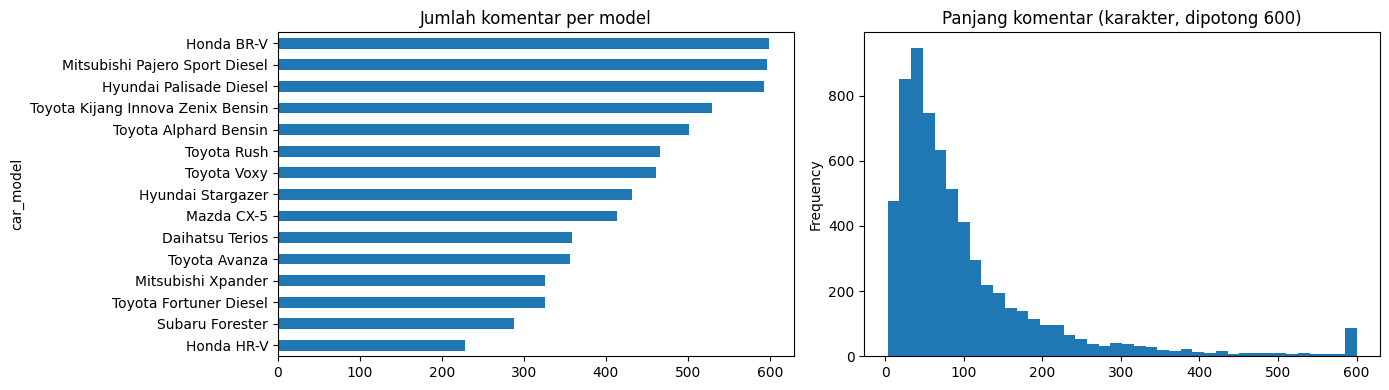


Sentimen baseline v1:
 sentiment
 0    1552
 1     908
-1     377
Name: count, dtype: int64


In [7]:
raw["review_text"] = raw["review_text"].fillna("").astype(str)
eda = raw.groupby("car_model").agg(komentar=("review_text", "size"),
                                   video=("video_id", "nunique"),
                                   median_karakter=("review_text", lambda s: int(s.str.len().median())))
display(eda.sort_values("komentar", ascending=False))
print("Total komentar:", len(raw), "| Total video:", raw["video_id"].nunique(), "| Total mobil:", raw["car_model"].nunique())
if "language" in raw.columns:
    print("Label bahasa heuristik v1:\n", raw["language"].value_counts())

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
eda["komentar"].sort_values().plot.barh(ax=ax[0], title="Jumlah komentar per model")
raw["review_text"].str.len().clip(upper=600).plot.hist(bins=40, ax=ax[1], title="Panjang komentar (karakter, dipotong 600)")
plt.tight_layout(); plt.show()

if "sentiment" in aspects_v1.columns:
    print("\nSentimen baseline v1:\n", aspects_v1["sentiment"].value_counts())

In [8]:
SLANG = {
    "gk": "tidak", "ga": "tidak", "gak": "tidak", "nggak": "tidak", "ngga": "tidak", "enggak": "tidak",
    "engga": "tidak", "tdk": "tidak", "kagak": "tidak", "gx": "tidak", "blm": "belum", "blum": "belum",
    "yg": "yang", "dgn": "dengan", "dg": "dengan", "utk": "untuk", "untk": "untuk", "bgt": "banget",
    "bngt": "banget", "tp": "tapi", "tpi": "tapi", "krn": "karena", "karna": "karena", "klo": "kalau",
    "kalo": "kalau", "kl": "kalau", "jd": "jadi", "jdi": "jadi", "sdh": "sudah", "udh": "sudah",
    "udah": "sudah", "dah": "sudah", "lbh": "lebih", "bnyk": "banyak", "jg": "juga", "sy": "saya",
    "gw": "saya", "gue": "saya", "gua": "saya", "aku": "saya", "ak": "saya", "aja": "saja", "aj": "saja",
    "lg": "lagi", "bs": "bisa", "bsa": "bisa", "sm": "sama", "dr": "dari", "dri": "dari", "emg": "memang",
    "emang": "memang", "bener": "benar", "pake": "pakai", "mantul": "mantap", "mantep": "mantap",
    "nyesel": "menyesal", "sparepart": "suku cadang", "spare part": "suku cadang", "onderdil": "suku cadang",
    "service": "servis", "kenceng": "kencang", "over price": "overprice", "komsumsi": "konsumsi", "worth it": "worth", "luar biasa": "luarbiasa",
}
SLANG_RE = re.compile(r"\b(" + "|".join(map(re.escape, sorted(SLANG, key=len, reverse=True))) + r")\b")

def light_clean(t):
    t = unicodedata.normalize("NFKC", html.unescape(str(t)))
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"@\S+", " ", t)
    t = re.sub(r"\b\d{1,2}:\d{2}(?::\d{2})?\b", " ", t)
    t = re.sub(r"[ \t]+", " ", t)
    return t.strip()

def normalize(t):
    t = light_clean(t).lower()
    t = re.sub(r"([a-z])\1{2,}", r"\1", t)
    t = re.sub(r"\b([a-z]{3,})2\b", r"\1 \1", t)
    t = re.sub(r"[^\w\s]", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    t = SLANG_RE.sub(lambda m: SLANG[m.group(1)], t)
    return t

for s in ["Mahal , tapi fitur keselamatan luar biasa 👍🏽", "irit bgt gak boros, mantappp", "7:43 kaki2 nya bunyi"]:
    print(repr(s), "->", repr(normalize(s)))

'Mahal , tapi fitur keselamatan luar biasa 👍🏽' -> 'mahal tapi fitur keselamatan luarbiasa'
'irit bgt gak boros, mantappp' -> 'irit banget tidak boros mantap'
'7:43 kaki2 nya bunyi' -> 'kaki kaki nya bunyi'


In [9]:
SPAM_RE = re.compile(r"\b(jangan lupa subscribe|subscribe balik|sub balik|cek channel|mampir ke channel|follow ig|giveaway|wa\.me|whatsapp|hubungi kami|info pemesanan)\b|\b08\d{8,11}\b", re.I)
EN_WORDS = {"the", "is", "and", "this", "that", "with", "for", "very", "car", "engine", "my", "it",
            "was", "have", "not", "of", "to", "in", "but", "you", "are", "i", "its", "what", "would"}
ID_WORDS = {"yang", "dan", "di", "ke", "dari", "untuk", "dengan", "banget", "tidak", "mobil", "saya",
            "kalau", "tapi", "sudah", "juga", "lebih", "kurang", "ini", "itu", "nya", "ada", "bisa", "mau"}
NON_LATIN_RE = re.compile(r"[\u0900-\u097F\u0600-\u06FF\u4E00-\u9FFF]")

def filter_reason(row):
    text, norm = row["light"], row["norm"]
    if SPAM_RE.search(text): return "spam_promosi"
    if NON_LATIN_RE.search(text): return "aksara_non_latin"
    words = norm.split()
    ws = set(words)
    en, idn = len(ws & EN_WORDS), len(ws & ID_WORDS)
    if en >= 3 and en > idn: return "bahasa_inggris"
    if len(words) < 3: return "terlalu_pendek"
    return "lolos"

df = raw[META_COLS].copy()
df["light"] = df["review_text"].map(light_clean)
df["norm"] = df["review_text"].map(normalize)
df["filter"] = df.apply(filter_reason, axis=1)
dup = df.duplicated(subset=["car_model", "norm"]) & (df["filter"] == "lolos")
df.loc[dup, "filter"] = "duplikat"

funnel = df["filter"].value_counts().rename("jumlah").to_frame()
funnel["persen"] = (funnel["jumlah"] / len(df) * 100).round(1)
display(funnel)
for reason in ["bahasa_inggris", "aksara_non_latin", "spam_promosi"]:
    ex = df.loc[df["filter"] == reason, "review_text"].head(3).tolist()
    if ex: print(reason, "→", [e[:90] for e in ex])

reviews = df[df["filter"] == "lolos"].reset_index(drop=True)
reviews["review_id"] = ["R" + str(i).zfill(5) for i in range(len(reviews))]
print("\nKomentar lolos:", len(reviews))

,jumlah,persen
filter,,
lolos,6040,93.3
terlalu_pendek,401,6.2
bahasa_inggris,19,0.3
duplikat,6,0.1
spam_promosi,5,0.1
aksara_non_latin,4,0.1


bahasa_inggris → ["Nice review and it's a beautiful family car but the only problem is can't afford 😢", 'Very good review.  The base model CVT variant in the Philippines has rear defogger. I am s', 'Otoreview very good review. Love from india but please add subtitles in english😎😎😎😎']
aksara_non_latin → ['One day beli ini buat ngaji, jalan bareng istri dan anak, hadir haul dan majlis. اللهم صل ', 'اَللَّهُمَّ صَلِّ عَلٰى سَيِّدِنَا مُحَمَّدٍ', 'Ya Alloh mobil impian ku\nاللهم صلي وسلم على سيدنا ومولنا محمد🤲']
spam_promosi → ['Info promo hitungan lainnya bisa langsung whatsapp Sepri Mitsubishi di https://wa.me/62813', 'bodi Xpander terlihat seperti adiknya pajero ya (versi kecilnya lah), tapi kalo mesin past', 'Untuk kerjasama  , silakan klik link dibawah untuk langsung terhubung ke Whatsapp saya  ya']

Komentar lolos: 6040


In [10]:
ASPECT_TERMS = {
    "comfort": ["nyaman", "kenyamanan", "empuk", "kabin", "suspensi", "bantingan", "limbung", "gluduk",
                "jok", "kursi", "senyap", "kedap", "peredam", "berisik", "bising", "ruang kaki", "legroom",
                "headroom", "lega", "sempit", "ac", "capek", "pegal"],
    "performance": ["performa", "tenaga", "tarikan", "akselerasi", "responsif", "mesin", "handling", "torsi",
                    "turbo", "nanjak", "tanjakan", "ngempos", "lemot", "loyo", "bertenaga", "cvt",
                    "transmisi", "rem", "pengereman", "setir", "kemudi", "kencang", "gesit", "lincah"],
    "fuel_economy": ["irit", "boros", "konsumsi", "bbm", "bensin", "solar", "efisien", "hemat", "km l",
                     "per liter", "sekilo", "pertalite", "pertamax", "dexlite"],
    "features": ["fitur", "kamera", "sensor", "infotainment", "head unit", "audio", "speaker", "airbag",
                 "adas", "sensing", "layar", "sunroof", "panoramic", "cruise", "keyless", "carplay",
                 "android auto", "safety", "keselamatan", "spion"],
    "design_interior": ["desain", "design", "tampilan", "bentuk", "muka", "wajah", "buritan", "lampu", "velg",
                        "interior", "eksterior", "dashboard", "bagasi", "material", "warna", "ganteng",
                        "cakep", "elegan", "sporty", "gagah", "kokoh"],
    "price_value": ["harga", "mahal", "murah", "value", "sepadan", "worth", "budget", "cicilan", "kredit",
                    "dp", "otr", "jt", "juta", "terjangkau", "kemahalan", "overprice", "harga bekas", "resale"],
    "reliability_maintenance": ["awet", "bandel", "tangguh", "rusak", "mogok", "rewel", "servis", "bengkel",
                                "perawatan", "suku cadang", "kaki kaki", "garansi", "trouble", "masalah",
                                "problem", "karat", "bunyi", "penyakit"],
}
ASPECT_RE = {a: re.compile(r"\b(?:" + "|".join(map(re.escape, ts)) + r")\b") for a, ts in ASPECT_TERMS.items()}

POSITIVE = {"nyaman", "irit", "hemat", "responsif", "bagus", "baik", "halus", "luas", "lega", "lengkap", "murah",
            "terjangkau", "awet", "bandel", "tangguh", "puas", "stabil", "mudah", "mantap", "enak", "keren",
            "ganteng", "cakep", "mewah", "elegan", "kencang", "bertenaga", "senyap", "kedap", "empuk", "worth",
            "sepadan", "rekomen", "recommended", "juara", "gesit", "lincah", "suka", "senang", "luarbiasa",
            "gagah", "kokoh", "canggih", "efisien", "sip", "top", "aman", "cocok", "terbaik", "mumpuni"}
NEGATIVE = {"boros", "mahal", "kemahalan", "keras", "berisik", "bising", "lambat", "lemot", "loyo", "ngempos",
            "buruk", "jelek", "sempit", "rusak", "sulit", "susah", "rewel", "limbung", "mogok", "kecewa",
            "menyesal", "parah", "trouble", "masalah", "gluduk", "getar", "karat", "overprice", "zonk", "ampas",
            "kurang", "minus", "kekurangan", "bunyi", "penyakit", "capek", "pegal", "bocor", "aneh", "ribet"}
NEGATIONS = {"tidak", "bukan", "belum", "kurang", "jangan", "tanpa"}
QUESTION_START = {"apa", "apakah", "berapa", "gimana", "bagaimana", "kapan", "dimana", "mana", "kenapa", "mengapa", "brp"}

CLAUSE_SPLIT = re.compile(r"[.!?\n;]+|\s(?:tapi|tp|tpi|namun|cuma|cuman|sayangnya|tetapi|sedangkan|walaupun|meskipun|sayang)\s", re.I)

MODEL_ALIAS = {
    "Toyota Avanza": ["avanza"], "Mitsubishi Xpander": ["xpander", "expander"], "Honda BR-V": ["br v", "brv"],
    "Toyota Rush": ["rush"], "Daihatsu Terios": ["terios"], "Hyundai Stargazer": ["stargazer"],
    "Honda HR-V": ["hr v", "hrv"], "Toyota Kijang Innova Zenix Bensin": ["innova", "zenix"],
    "Toyota Voxy": ["voxy"], "Mazda CX-5": ["cx 5", "cx5"], "Subaru Forester": ["forester"],
    "Toyota Fortuner Diesel": ["fortuner"], "Mitsubishi Pajero Sport Diesel": ["pajero"],
    "Hyundai Palisade Diesel": ["palisade"], "Toyota Alphard Bensin": ["alphard"],
}
ALIAS_RE = {m: re.compile(r"\b(?:" + "|".join(map(re.escape, a)) + r")\b") for m, a in MODEL_ALIAS.items()}

assert set(MODEL_ALIAS) == set(CATALOG["car_model"]), "Alias model tidak sama dengan sheet catalog_mobil"

def mentions_other_model(norm, own):
    own_hit = bool(ALIAS_RE[own].search(norm))
    other_hit = any(r.search(norm) for m, r in ALIAS_RE.items() if m != own)
    return other_hit and not own_hit

def is_question(light, norm):
    words = norm.split()
    has_opinion = any(w in POSITIVE or w in NEGATIVE for w in words)
    asks = light.strip().endswith("?") or (words and words[0] in QUESTION_START)
    return asks and not has_opinion

rows, drop_counter = [], Counter()
for r in reviews.itertuples():
    parts = [p.strip(" ,-") for p in CLAUSE_SPLIT.split(r.light) if p and p.strip(" ,-")]
    for ci, clause in enumerate(parts):
        n = normalize(clause)
        if len(n.split()) < 2:
            continue
        found = [a for a in ASPECTS if ASPECT_RE[a].search(n)]
        if not found:
            continue
        if is_question(clause, n):
            drop_counter["pertanyaan"] += 1; continue
        if mentions_other_model(n, r.car_model):
            drop_counter["model_lain"] += 1; continue
        for a in found:
            rows.append({"clause_id": f"{r.review_id}_{ci}_{a}", "review_id": r.review_id,
                         "car_model": r.car_model, "aspect": a, "clause": clause, "clause_norm": n,
                         "video_id": r.video_id, "published_date": r.published_date, "like_count": r.like_count,
                         "source": r.source, "source_url": r.source_url})

clauses = pd.DataFrame(rows)
print("Klausa beraspek:", len(clauses), "| dari", clauses["review_id"].nunique(), "komentar")
print("Klausa dibuang:", dict(drop_counter))
display(pd.crosstab(clauses["car_model"], clauses["aspect"]).reindex(columns=ASPECTS))

Klausa beraspek: 4044 | dari 2185 komentar
Klausa dibuang: {'model_lain': 173, 'pertanyaan': 35}


aspect,comfort,performance,fuel_economy,features,design_interior,price_value,reliability_maintenance
car_model,,,,,,,
Daihatsu Terios,74,54,33,9,39,22,67
Honda BR-V,71,74,5,87,65,77,28
Honda HR-V,35,38,15,20,28,41,65
Hyundai Palisade Diesel,18,27,66,17,41,19,14
Hyundai Stargazer,40,34,14,39,114,39,11
Mazda CX-5,41,38,15,29,36,38,24
Mitsubishi Pajero Sport Diesel,43,34,31,20,41,27,28
Mitsubishi Xpander,62,47,28,42,45,27,89
Subaru Forester,11,37,7,7,24,14,10


In [11]:
def lexicon_sentiment(norm):
    words = str(norm).split()
    score = 0
    for i, w in enumerate(words):
        if w == "kurang" and any(x in POSITIVE or x in NEGATIVE for x in words[i + 1:i + 3]):
            continue
        pol = 1 if w in POSITIVE else (-1 if w in NEGATIVE else 0)
        if pol == 0:
            continue
        if any(x in NEGATIONS for x in words[max(0, i - 3):i]):
            pol = -pol
        score += pol
    return int(np.sign(score))

clauses["sent_lexicon"] = clauses["clause_norm"].map(lexicon_sentiment)
for s in ["tidak boros", "kurang nyaman", "mahal", "fitur keselamatan luar biasa", "suspensi tidak keras", "warnanya merah"]:
    print(f"{s!r:40} -> {lexicon_sentiment(normalize(s))}")
print(clauses["sent_lexicon"].value_counts())

'tidak boros'                            -> 1
'kurang nyaman'                          -> -1
'mahal'                                  -> -1
'fitur keselamatan luar biasa'           -> 1
'suspensi tidak keras'                   -> 1
'warnanya merah'                         -> 0
sent_lexicon
 0    1793
 1    1602
-1     649
Name: count, dtype: int64


In [12]:
pretrained_clf = None
try:
    import torch
    from transformers import pipeline
    DEVICE = 0 if torch.cuda.is_available() else -1
    pretrained_clf = pipeline("text-classification", model=PRETRAINED_SENTIMENT, device=DEVICE,
                              truncation=True, max_length=128)
    print("Model pretrained dimuat. GPU:", DEVICE == 0, "| label:", pretrained_clf.model.config.id2label)
except Exception as e:
    print("Model pretrained tidak dapat dimuat, dilewati:", repr(e)[:200])

def label_to_int(lbl):
    l = str(lbl).lower()
    return 1 if "pos" in l else (-1 if "neg" in l else 0)

def predict_pretrained(texts, bs=64):
    out = pretrained_clf(list(texts), batch_size=bs)
    return [label_to_int(o["label"]) for o in out]

if pretrained_clf is not None:
    t0 = time.time()
    clauses["sent_pretrained"] = predict_pretrained(clauses["clause"])
    print(f"Selesai {len(clauses)} klausa dalam {time.time() - t0:.0f} detik")
    print(clauses["sent_pretrained"].value_counts())
    print("Kesepakatan dengan leksikon:", round((clauses.sent_pretrained == clauses.sent_lexicon).mean(), 3))

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/328 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/808k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/467k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.38M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Model pretrained dimuat. GPU: True | label: {0: 'positive', 1: 'neutral', 2: 'negative'}
Selesai 4044 klausa dalam 13 detik
sent_pretrained
 1    1924
-1    1395
 0     725
Name: count, dtype: int64
Kesepakatan dengan leksikon: 0.602


In [13]:
ANNOT_FILE = f"{OUT_DIR}/anotasi_manual.csv"
if not os.path.exists(ANNOT_FILE):
    sample = pd.concat([g.sample(min(len(g), N_ANNOT_PER_ASPECT), random_state=SEED)
                        for _, g in clauses.groupby("aspect")])
    sample = sample.sample(frac=1, random_state=SEED)[["clause_id", "car_model", "aspect", "clause"]]
    sample["label"] = ""
    sample["label_2"] = ""
    sample.to_csv(ANNOT_FILE, index=False)
    print("File anotasi dibuat:", ANNOT_FILE, "| baris:", len(sample))
else:
    print("File anotasi sudah ada:", ANNOT_FILE)
pd.read_csv(ANNOT_FILE).head()

File anotasi dibuat: /content/uts_nlp/output/anotasi_manual.csv | baris: 1050


,clause_id,car_model,aspect,clause,label,label_2
0,R01497_1_features,Toyota Rush,features,jujur saya bukan penggila byk fitur teknologi di mobil,NaN,NaN
1,R04044_1_performance,Subaru Forester,performance,cvt rantai katanya gimana tuh koh,NaN,NaN
2,R05646_2_fuel_economy,Toyota Alphard Bensin,fuel_economy,tidak masuk akal untuk toyota memproduksi dan memasarkan alphard yang lebih boros saat mereka sudah punya yang jauh ...,NaN,NaN
3,R02896_0_features,Toyota Kijang Innova Zenix Bensin,features,cuma kurang cruise control aja,NaN,NaN
4,R03211_0_comfort,Toyota Voxy,comfort,Ternyata masalah ac sudah common di Toyota ya,NaN,NaN


In [14]:
def start_labeling(path=ANNOT_FILE, col="label"):
    """Widget pelabelan. Setiap klik langsung tersimpan ke CSV."""
    import ipywidgets as w
    from IPython.display import display as _display, clear_output
    ann = pd.read_csv(path, dtype=str).fillna("")
    history = []
    out = w.Output()
    progress = w.HTML()

    def next_idx():
        todo = ann.index[ann[col] == ""]
        return todo[0] if len(todo) else None

    def render():
        with out:
            clear_output()
            i = next_idx()
            done = (ann[col] != "").sum()
            progress.value = f"<b>{done}/{len(ann)}</b> terlabel"
            if i is None:
                print("Semua sampel sudah dilabeli."); return
            r = ann.loc[i]
            print(f"[{r.car_model}]  Aspek: {ASPECT_LABEL[r.aspect]}\n\n{r.clause}")

    def make(val):
        def click(_):
            i = next_idx()
            if i is None: return
            ann.at[i, col] = val; history.append(i)
            ann.to_csv(path, index=False); render()
        return click

    def undo(_):
        if history:
            ann.at[history.pop(), col] = ""; ann.to_csv(path, index=False); render()

    btns = []
    for text, val, style in [("Positif", "1", "success"), ("Netral", "0", ""), ("Negatif", "-1", "danger"),
                             ("Bukan aspek ini", "x", "warning")]:
        b = w.Button(description=text, button_style=style); b.on_click(make(val)); btns.append(b)
    ub = w.Button(description="Undo"); ub.on_click(undo); btns.append(ub)
    _display(progress, out, w.HBox(btns)); render()

In [15]:
def norm_label(v):
    s = str(v).strip().lower()
    if s in {"", "nan", "none"}: return None
    if s in {"x", "bukan", "irrelevant", "tidak relevan"}: return "x"
    if s.startswith("pos"): return "1"
    if s.startswith("neg"): return "-1"
    if s.startswith("net"): return "0"
    try:
        return str(int(float(s)))
    except ValueError:
        return None

aspect_precision_df, kappa_info = None, None
ann = pd.read_csv(ANNOT_FILE, dtype=str)
ann["label"] = ann["label"].map(norm_label)
ann["label_2"] = ann.get("label_2", pd.Series(dtype=str)).map(norm_label)
labeled = ann[ann["label"].notna()].copy()
print("Sampel terlabel:", len(labeled), "dari", len(ann))

if len(labeled):
    prec = labeled.assign(benar=labeled["label"] != "x").groupby("aspect")["benar"].agg(["mean", "size"])
    prec.columns = ["presisi_deteksi_aspek", "n"]
    aspect_precision_df = prec.round(3).reset_index()
    display(prec.round(3))
    both = labeled[labeled["label_2"].notna()]
    if len(both) >= 30:
        kappa_info = {"n": len(both), "cohen_kappa": round(cohen_kappa_score(both["label"], both["label_2"]), 3)}
        print("Cohen's kappa (n=%d): %.3f" % (kappa_info["n"], kappa_info["cohen_kappa"]))

gold = labeled[labeled["label"].isin(["1", "0", "-1"])].copy()
gold["y"] = gold["label"].astype(int)
gold = gold.merge(clauses[["clause_id", "clause_norm"]], on="clause_id", how="left")
gold["clause_norm"] = gold["clause_norm"].fillna(gold["clause"].map(normalize))
if len(gold):
    print("Distribusi label sentimen:\n", gold["y"].value_counts())

Sampel terlabel: 0 dari 1050


In [16]:
EPOCHS, LR, BATCH, MAX_LEN = 4, 2e-5, 16, 128
LABEL2ID = {-1: 0, 0: 1, 1: 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}
ft_model, ft_tok, train_df, val_df, test_df = None, None, None, None, None
train_log_df = None

def stratified_split(d):
    strat = d["y"] if d["y"].value_counts().min() >= 3 else None
    tr, tmp = train_test_split(d, test_size=0.30, random_state=SEED, stratify=strat)
    strat2 = tmp["y"] if strat is not None else None
    va, te = train_test_split(tmp, test_size=0.50, random_state=SEED, stratify=strat2)
    return tr.reset_index(drop=True), va.reset_index(drop=True), te.reset_index(drop=True)

if len(gold) >= MIN_LABELED_FOR_FINETUNE:
    train_df, val_df, test_df = stratified_split(gold)
    print("Train/Val/Test:", len(train_df), len(val_df), len(test_df))
else:
    print(f"Label sentimen baru {len(gold)}; minimal {MIN_LABELED_FOR_FINETUNE} untuk fine-tuning. "
          "Lanjutkan anotasi di bagian 12, lalu jalankan ulang dari bagian 13.")

Label sentimen baru 0; minimal 300 untuk fine-tuning. Lanjutkan anotasi di bagian 12, lalu jalankan ulang dari bagian 13.


In [17]:
if train_df is not None:
    import torch
    from torch.utils.data import DataLoader
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
    from sklearn.utils.class_weight import compute_class_weight

    torch.manual_seed(SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ft_tok = AutoTokenizer.from_pretrained(INDOBERT)
    ft_model = AutoModelForSequenceClassification.from_pretrained(
        INDOBERT, num_labels=3, id2label={0: "negatif", 1: "netral", 2: "positif"},
        label2id={"negatif": 0, "netral": 1, "positif": 2}).to(device)

    def to_records(d):
        return [{"a": ASPECT_LABEL[a], "t": t, "y": LABEL2ID[y]} for a, t, y in zip(d["aspect"], d["clause"], d["y"])]

    def collate(batch):
        enc = ft_tok([b["a"] for b in batch], [b["t"] for b in batch], truncation=True,
                     max_length=MAX_LEN, padding=True, return_tensors="pt")
        enc["labels"] = torch.tensor([b["y"] for b in batch])
        return enc

    train_dl = DataLoader(to_records(train_df), batch_size=BATCH, shuffle=True, collate_fn=collate)
    val_dl = DataLoader(to_records(val_df), batch_size=64, collate_fn=collate)

    cw = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=train_df["y"].map(LABEL2ID))
    loss_fn = torch.nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float).to(device))
    opt = torch.optim.AdamW(ft_model.parameters(), lr=LR, weight_decay=0.01)
    total = len(train_dl) * EPOCHS
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)

    def run_eval(dl):
        ft_model.eval(); preds, gold_y = [], []
        with torch.no_grad():
            for b in dl:
                b = {k: v.to(device) for k, v in b.items()}
                logits = ft_model(**{k: v for k, v in b.items() if k != "labels"}).logits
                preds += logits.argmax(-1).tolist(); gold_y += b["labels"].tolist()
        return f1_score(gold_y, preds, average="macro")

    best_f1, best_state, log = -1, None, []
    for ep in range(1, EPOCHS + 1):
        ft_model.train(); run_loss = 0
        for b in train_dl:
            b = {k: v.to(device) for k, v in b.items()}
            logits = ft_model(**{k: v for k, v in b.items() if k != "labels"}).logits
            loss = loss_fn(logits, b["labels"])
            loss.backward(); torch.nn.utils.clip_grad_norm_(ft_model.parameters(), 1.0)
            opt.step(); sched.step(); opt.zero_grad(); run_loss += loss.item()
        vf1 = run_eval(val_dl)
        log.append({"epoch": ep, "train_loss": run_loss / len(train_dl), "val_macro_f1": vf1})
        print(f"Epoch {ep} | loss {run_loss / len(train_dl):.4f} | val macro-F1 {vf1:.4f}")
        if vf1 > best_f1:
            best_f1 = vf1
            best_state = {k: v.detach().cpu().clone() for k, v in ft_model.state_dict().items()}

    ft_model.load_state_dict(best_state)
    ft_model.save_pretrained(f"{OUT_DIR}/indobert_absa"); ft_tok.save_pretrained(f"{OUT_DIR}/indobert_absa")
    train_log_df = pd.DataFrame(log)
    pd.DataFrame(log).set_index("epoch").plot(subplots=True, figsize=(10, 4), title="Kurva pelatihan"); plt.show()

def predict_finetuned(aspects, texts, bs=64):
    import torch
    device = next(ft_model.parameters()).device
    ft_model.eval(); preds = []
    aspects, texts = list(aspects), list(texts)
    with torch.no_grad():
        for i in range(0, len(texts), bs):
            enc = ft_tok([ASPECT_LABEL[a] for a in aspects[i:i + bs]], texts[i:i + bs], truncation=True,
                         max_length=MAX_LEN, padding=True, return_tensors="pt").to(device)
            preds += [ID2LABEL[p] for p in ft_model(**enc).logits.argmax(-1).tolist()]
    return preds

In [18]:
ENGINES = {"lexicon": lambda d: d["clause_norm"].map(lexicon_sentiment).tolist()}
if pretrained_clf is not None:
    ENGINES["pretrained"] = lambda d: predict_pretrained(d["clause"])
if ft_model is not None:
    ENGINES["indobert_finetuned"] = lambda d: predict_finetuned(d["aspect"], d["clause"])

eval_rows, test_preds = [], {}
eval_table, cls_report_df = None, None
if test_df is not None:
    for name, fn in ENGINES.items():
        pv, pt = fn(val_df), fn(test_df)
        test_preds[name] = pt
        eval_rows.append({"model": name,
                          "val_macro_f1": f1_score(val_df["y"], pv, average="macro"),
                          "test_macro_f1": f1_score(test_df["y"], pt, average="macro"),
                          "test_accuracy": np.mean(np.array(pt) == test_df["y"].values)})
    eval_table = pd.DataFrame(eval_rows).set_index("model").round(4)
    display(eval_table)
    BEST_ENGINE = eval_table["val_macro_f1"].idxmax()
    print("Model terpilih (val macro-F1 tertinggi):", BEST_ENGINE)
    _rep = classification_report(test_df["y"], test_preds[BEST_ENGINE], labels=[-1, 0, 1],
                                 target_names=["negatif", "netral", "positif"], digits=3,
                                 output_dict=True, zero_division=0)
    cls_report_df = pd.DataFrame(_rep).T.round(3).reset_index().rename(columns={"index": "kelas"})
    display(cls_report_df)
    cm = confusion_matrix(test_df["y"], test_preds[BEST_ENGINE], labels=[-1, 0, 1])
    fig, ax = plt.subplots(figsize=(4, 4)); ax.imshow(cm, cmap="Blues")
    for i in range(3):
        for j in range(3): ax.text(j, i, cm[i, j], ha="center", va="center")
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels(["neg", "net", "pos"]); ax.set_yticklabels(["neg", "net", "pos"])
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual"); ax.set_title(f"Confusion matrix: {BEST_ENGINE}")
    plt.show()
    err = test_df.assign(pred=test_preds[BEST_ENGINE])
    display(err[err["pred"] != err["y"]][["car_model", "aspect", "clause", "y", "pred"]].head(15))
else:
    BEST_ENGINE = "pretrained" if "pretrained" in ENGINES else "lexicon"
    print("Belum ada data uji berlabel. Prediksi memakai:", BEST_ENGINE)

Belum ada data uji berlabel. Prediksi memakai: pretrained


In [19]:
if BEST_ENGINE == "lexicon":
    clauses["sentiment"] = clauses["sent_lexicon"]
elif BEST_ENGINE == "pretrained":
    clauses["sentiment"] = clauses["sent_pretrained"]
else:
    clauses["sentiment"] = predict_finetuned(clauses["aspect"], clauses["clause"])
clauses["engine"] = BEST_ENGINE
print(clauses["sentiment"].value_counts())
pd.crosstab(clauses["aspect"], clauses["sentiment"]).reindex(ASPECTS)

sentiment
 1    1924
-1    1395
 0     725
Name: count, dtype: int64


sentiment,-1,0,1
aspect,,,
comfort,220,69,399
performance,219,141,281
fuel_economy,131,110,204
features,176,85,173
design_interior,195,127,310
price_value,232,132,272
reliability_maintenance,222,61,285


Sel tanpa skor (data kurang): 2 dari 105


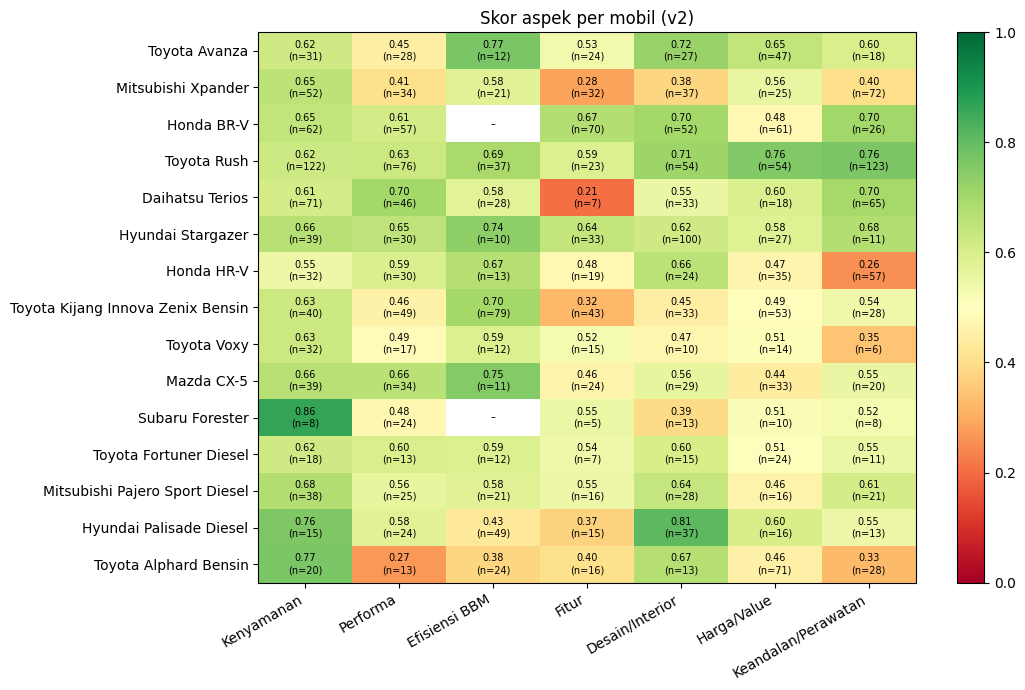

In [20]:
agg = clauses.groupby(["car_model", "aspect"])["sentiment"].agg(
    n="size", pos=lambda s: (s == 1).sum(), neu=lambda s: (s == 0).sum(), neg=lambda s: (s == -1).sum()).reset_index()
agg["n_opini"] = agg["pos"] + agg["neg"]
tot = agg.groupby("aspect")[["pos", "n_opini"]].sum()
p0 = tot["pos"] / tot["n_opini"].clip(lower=1)
agg["p0"] = agg["aspect"].map(p0)
agg["score"] = (agg["pos"] + PRIOR_STRENGTH * agg["p0"]) / (agg["n_opini"] + PRIOR_STRENGTH)
agg.loc[agg["n_opini"] < MIN_OPINION, "score"] = np.nan

score_table = agg.pivot(index="car_model", columns="aspect", values="score").reindex(index=CATALOG.car_model, columns=ASPECTS)
count_table = agg.pivot(index="car_model", columns="aspect", values="n_opini").reindex(index=CATALOG.car_model, columns=ASPECTS).fillna(0).astype(int)
score_table.index.name = count_table.index.name = "car_model"
car_counts = agg.groupby("car_model")[["pos", "neu", "neg"]].sum().reindex(CATALOG["car_model"]).fillna(0).astype(int)
car_counts.columns = ["opini_positif", "opini_netral", "opini_negatif"]
car_counts["jumlah_opini"] = car_counts["opini_positif"] + car_counts["opini_negatif"]

print("Sel tanpa skor (data kurang):", int(score_table.isna().sum().sum()), "dari", score_table.size)
fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(score_table.values.astype(float), cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(ASPECTS))); ax.set_xticklabels([ASPECT_LABEL[a] for a in ASPECTS], rotation=30, ha="right")
ax.set_yticks(range(len(score_table))); ax.set_yticklabels(score_table.index)
for i in range(score_table.shape[0]):
    for j in range(score_table.shape[1]):
        v = score_table.iat[i, j]
        ax.text(j, i, "–" if pd.isna(v) else f"{v:.2f}\n(n={count_table.iat[i, j]})", ha="center", va="center", fontsize=7)
plt.colorbar(im); ax.set_title("Skor aspek per mobil (v2)"); plt.tight_layout(); plt.show()

In [21]:
def normalize_weights(w, keys=ASPECTS):
    """Bobot -> proporsi non-negatif dengan total 1 (= 100%)."""
    s = pd.Series(w, dtype=float).reindex(list(keys)).fillna(0)
    if (s < 0).any() or s.sum() <= 0:
        raise ValueError("Bobot harus non-negatif dan totalnya > 0")
    return s / s.sum()

PRESETS = {
    "Seimbang":        {a: 1 for a in ASPECTS},
    "Keluarga hemat":  {"comfort": .25, "fuel_economy": .25, "price_value": .2, "reliability_maintenance": .15,
                        "features": .05, "performance": .05, "design_interior": .05},
    "Performa":        {"performance": .4, "comfort": .15, "features": .15, "design_interior": .1,
                        "fuel_economy": .05, "price_value": .05, "reliability_maintenance": .1},
    "Default v1":      {"comfort": .25, "performance": .15, "fuel_economy": .20, "features": .10,
                        "design_interior": .10, "price_value": .10, "reliability_maintenance": .10},
}
w_exact = pd.DataFrame({k: normalize_weights(v) * 100 for k, v in PRESETS.items()}).rename(index=ASPECT_LABEL)
assert np.allclose(w_exact.sum(), 100), "Bobot ternormalisasi harus berjumlah 100%"
w_pct = w_exact.round(1)
w_pct.loc["TOTAL (%)"] = w_exact.sum().round(1)
display(w_pct)

,Seimbang,Keluarga hemat,Performa,Default v1
Kenyamanan,14.3,25.0,15.0,25.0
Performa,14.3,5.0,40.0,15.0
Efisiensi BBM,14.3,25.0,5.0,20.0
Fitur,14.3,5.0,15.0,10.0
Desain/Interior,14.3,5.0,10.0,10.0
Harga/Value,14.3,20.0,5.0,10.0
Keandalan/Perawatan,14.3,15.0,10.0,10.0
TOTAL (%),100.0,100.0,100.0,100.0


In [22]:
def topsis(X, weights):
    X = X.astype(float)
    w = normalize_weights(weights, X.columns)
    R = X / np.sqrt((X ** 2).sum()).replace(0, 1)
    V = R * w
    d_best = np.sqrt(((V - V.max()) ** 2).sum(axis=1))
    d_worst = np.sqrt(((V - V.min()) ** 2).sum(axis=1))
    return (d_worst / (d_best + d_worst).replace(0, np.nan)).fillna(0.5)

def filter_catalog(cat=None, body=None, fuel=None, powertrain=None, min_seats=None, price_lo=None, price_hi=None):
    """Filter kandidat. Nilai kosong/None = tidak difilter. Harga dalam juta Rp, rentang dianggap beririsan
    dengan [price_min, price_max]; price_max=inf berarti tanpa batas atas ("1 miliar+")."""
    c = (CATALOG if cat is None else cat).copy()
    if body: c = c[c["body"].isin(body)]
    if fuel: c = c[c["fuel"].isin(fuel)]
    if powertrain: c = c[c["powertrain"].isin(powertrain)]
    if min_seats: c = c[c["seats"] >= min_seats]
    if price_lo is not None: c = c[c["price_max"] >= price_lo]
    if price_hi is not None: c = c[c["price_min"] <= price_hi]
    return c

def recommend(weights, body=None, fuel=None, powertrain=None, min_seats=None, price_lo=None, price_hi=None, top_k=5):
    cand = filter_catalog(None, body, fuel, powertrain, min_seats, price_lo, price_hi)
    if len(cand) < 2:
        print("Kandidat kurang dari 2, longgarkan filter."); return cand
    X = score_table.loc[cand["car_model"]]
    imputed = X.isna()
    X = X.fillna(score_table.mean())
    s = topsis(X, weights)
    res = cand.set_index("car_model").assign(topsis=s).sort_values("topsis", ascending=False)
    res["aspek_data_kurang"] = [", ".join(ASPECT_LABEL[a] for a in ASPECTS if imputed.loc[m, a]) for m in res.index]
    res = res.join(car_counts[["jumlah_opini", "opini_positif", "opini_negatif"]])
    res.insert(0, "peringkat", range(1, len(res) + 1))
    return res[["peringkat", "topsis", "price_band", "body", "fuel", "powertrain", "seats",
                "jumlah_opini", "opini_positif", "opini_negatif", "aspek_data_kurang"]].head(top_k)

print("Skenario 1: keluarga, harga sampai Rp400 juta, minimal 7 kursi")
display(recommend(PRESETS["Keluarga hemat"], price_hi=400, min_seats=7))
print("Skenario 2: preset Seimbang, filter default Streamlit (SUV, ICE, harga Rp500 juta – Rp1 miliar+)")
display(recommend(PRESETS["Seimbang"], body=["SUV"], powertrain=["ICE"], price_lo=500))
print("Skenario 3: performa, SUV, tanpa batas harga")
display(recommend(PRESETS["Performa"], body=["SUV"]))

Skenario 1: keluarga, harga sampai Rp400 juta, minimal 7 kursi


,peringkat,topsis,price_band,body,fuel,powertrain,seats,jumlah_opini,opini_positif,opini_negatif,aspek_data_kurang
car_model,,,,,,,,,,,
Toyota Rush,1,0.807519,Rp200–400 juta,SUV,Bensin,ICE,7,489,340,149,
Toyota Avanza,2,0.640569,Rp200–300 juta,MPV,Bensin,ICE,7,187,116,71,
Hyundai Stargazer,3,0.634480,Rp200–400 juta,MPV,Bensin,ICE,7,250,162,88,
Honda BR-V,4,0.460393,Rp200–400 juta,SUV,Bensin,ICE,7,332,211,121,Efisiensi BBM
Daihatsu Terios,5,0.447521,Rp200–400 juta,SUV,Bensin,ICE,7,268,167,101,


Skenario 2: preset Seimbang, filter default Streamlit (SUV, ICE, harga Rp500 juta – Rp1 miliar+)


,peringkat,topsis,price_band,body,fuel,powertrain,seats,jumlah_opini,opini_positif,opini_negatif,aspek_data_kurang
car_model,,,,,,,,,,,
Mitsubishi Pajero Sport Diesel,1,0.614636,Rp500–800 juta,SUV,Diesel,ICE,7,165,99,66,
Mazda CX-5,2,0.595427,Rp500–800 juta,SUV,Bensin,ICE,5,190,110,80,
Hyundai Palisade Diesel,3,0.595369,Rp800–1000 juta,SUV,Diesel,ICE,7,169,99,70,
Toyota Fortuner Diesel,4,0.579848,Rp500–800 juta,SUV,Diesel,ICE,7,100,57,43,
Subaru Forester,5,0.510577,Rp700–800 juta,SUV,Bensin,ICE,5,70,36,34,Efisiensi BBM


Skenario 3: performa, SUV, tanpa batas harga


,peringkat,topsis,price_band,body,fuel,powertrain,seats,jumlah_opini,opini_positif,opini_negatif,aspek_data_kurang
car_model,,,,,,,,,,,
Toyota Rush,1,0.701680,Rp200–400 juta,SUV,Bensin,ICE,7,489,340,149,
Honda BR-V,2,0.689175,Rp200–400 juta,SUV,Bensin,ICE,7,332,211,121,Efisiensi BBM
Mazda CX-5,3,0.613234,Rp500–800 juta,SUV,Bensin,ICE,5,190,110,80,
Toyota Fortuner Diesel,4,0.565646,Rp500–800 juta,SUV,Diesel,ICE,7,100,57,43,
Mitsubishi Pajero Sport Diesel,5,0.537651,Rp500–800 juta,SUV,Diesel,ICE,7,165,99,66,


In [23]:
X_all = score_table.fillna(score_table.mean())
base_w = PRESETS["Default v1"]
base = topsis(X_all, base_w)
sens = []
for a in ASPECTS:
    for f in [0.8, 1.2]:
        w = dict(base_w); w[a] *= f
        s = topsis(X_all, w)
        sens.append({"aspek": ASPECT_LABEL[a], "faktor": f,
                     "spearman": spearmanr(base, s.reindex(base.index)).correlation,
                     "top1_sama": s.idxmax() == base.idxmax()})
sens = pd.DataFrame(sens)
display(sens.round(3))
print("Rerata Spearman:", round(sens["spearman"].mean(), 3), "| Top-1 stabil:", f"{sens['top1_sama'].mean():.0%}")

cmp = pd.DataFrame({"skor_v1": rank_v1, "skor_v2": base})
print("Mobil tanpa skor v1 (dikeluarkan dari perbandingan):", cmp[cmp["skor_v1"].isna()].index.tolist())
cmp = cmp.dropna()
cmp["rank_v1"] = cmp["skor_v1"].rank(ascending=False).astype(int)
cmp["rank_v2"] = cmp["skor_v2"].rank(ascending=False).astype(int)
cmp["selisih_rank"] = cmp["rank_v1"] - cmp["rank_v2"]
cmp = cmp.sort_values("rank_v2")
display(cmp.round(3))
print("Spearman v1 vs v2:", round(spearmanr(cmp["skor_v1"], cmp["skor_v2"]).correlation, 3))
print("Total pasangan aspek-sentimen v1:", len(aspects_v1), "| v2:", len(clauses))

PROF_A, PROF_B = "Keluarga hemat", "Performa"
sa, sb = topsis(X_all, PRESETS[PROF_A]), topsis(X_all, PRESETS[PROF_B])
pers = pd.DataFrame({f"skor_{PROF_A}": sa, f"skor_{PROF_B}": sb})
pers[f"rank_{PROF_A}"] = sa.rank(ascending=False).astype(int)
pers[f"rank_{PROF_B}"] = sb.rank(ascending=False).astype(int)
pers["selisih_rank"] = pers[f"rank_{PROF_A}"] - pers[f"rank_{PROF_B}"]
pers = pers.sort_values(f"rank_{PROF_A}")
display(pers.round(3))
print("Spearman antar profil:", round(spearmanr(sa, sb.reindex(sa.index)).correlation, 3),
      "| Top-1:", sa.idxmax(), "vs", sb.idxmax(),
      "| Top-3 beririsan:", len(set(sa.nlargest(3).index) & set(sb.nlargest(3).index)), "dari 3")

,aspek,faktor,spearman,top1_sama
0,Kenyamanan,0.8,0.989,True
1,Kenyamanan,1.2,0.971,True
2,Performa,0.8,0.993,True
3,Performa,1.2,0.989,True
4,Efisiensi BBM,0.8,0.993,True
5,Efisiensi BBM,1.2,0.986,True
6,Fitur,0.8,0.975,True
7,Fitur,1.2,1.000,True
8,Desain/Interior,0.8,0.986,True
9,Desain/Interior,1.2,0.996,True


Rerata Spearman: 0.99 | Top-1 stabil: 100%
Mobil tanpa skor v1 (dikeluarkan dari perbandingan): []


,skor_v1,skor_v2,rank_v1,rank_v2,selisih_rank
car_model,,,,,
Hyundai Stargazer,0.631,0.693,4,1,3
Toyota Rush,0.564,0.674,7,2,5
Honda BR-V,0.626,0.622,5,3,2
Mazda CX-5,0.621,0.609,6,4,2
Toyota Avanza,0.682,0.586,2,5,-3
Subaru Forester,0.541,0.585,9,6,3
Mitsubishi Pajero Sport Diesel,0.559,0.555,8,7,1
Toyota Fortuner Diesel,0.480,0.528,13,8,5
Hyundai Palisade Diesel,0.806,0.518,1,9,-8


Spearman v1 vs v2: 0.471
Total pasangan aspek-sentimen v1: 2837 | v2: 4044


,skor_Keluarga hemat,skor_Performa,rank_Keluarga hemat,rank_Performa,selisih_rank
car_model,,,,,
Toyota Rush,0.705,0.789,1,2,-1
Hyundai Stargazer,0.664,0.822,2,1,1
Toyota Avanza,0.642,0.487,3,12,-9
Subaru Forester,0.569,0.520,4,10,-6
Mazda CX-5,0.541,0.745,5,4,1
Honda BR-V,0.541,0.771,6,3,3
Daihatsu Terios,0.523,0.670,7,6,1
Toyota Kijang Innova Zenix Bensin,0.500,0.409,8,13,-5
Mitsubishi Pajero Sport Diesel,0.475,0.662,9,7,2


Spearman antar profil: 0.593 | Top-1: Toyota Rush vs Hyundai Stargazer | Top-3 beririsan: 2 dari 3


In [24]:
def write_blocks(w, sheet, blocks):
    row = 0
    for title, d, idx in blocks:
        pd.DataFrame([[title]]).to_excel(w, sheet_name=sheet, startrow=row, index=False, header=False)
        xl_clean(d).to_excel(w, sheet_name=sheet, startrow=row + 1, index=idx)
        row += len(d) + 4

ranking_out = recommend(PRESETS["Default v1"], top_k=len(CATALOG))
catalog_out = CATALOG.assign(price_max=CATALOG["price_max"].replace(np.inf, np.nan))
opini_out = count_table.add_prefix("n_").join(car_counts)

eval_blocks = [("Ringkasan anotasi dan model terpilih", pd.DataFrame([{
    "sampel_terlabel": int(len(labeled)), "sampel_gold_sentimen": int(len(gold)),
    "model_sentimen_terpakai": BEST_ENGINE}]), False)]
if eval_table is not None:        eval_blocks.append(("Evaluasi engine sentimen (data uji berlabel)", eval_table.reset_index(), False))
if cls_report_df is not None:     eval_blocks.append((f"Precision / recall / F1 per kelas ({BEST_ENGINE})", cls_report_df, False))
if aspect_precision_df is not None: eval_blocks.append(("Presisi deteksi aspek (dari anotasi)", aspect_precision_df, False))
if kappa_info:                    eval_blocks.append(("Kesepakatan antar-anotator", pd.DataFrame([kappa_info]), False))
if train_log_df is not None:      eval_blocks.append(("Log pelatihan IndoBERT", train_log_df, False))
if eval_table is None:
    eval_blocks.append(("Catatan", pd.DataFrame({"catatan": [
        "Belum ada data uji berlabel (anotasi < MIN_LABELED_FOR_FINETUNE); engine sentimen dipilih tanpa evaluasi F1."]}), False))

with pd.ExcelWriter(OUTPUT_XLSX, engine="openpyxl") as w:
    xl_clean(raw).to_excel(w, sheet_name="1_data_mentah", index=False)
    xl_clean(reviews.drop(columns=["filter"])).to_excel(w, sheet_name="2_hasil_prepro", index=False)
    xl_clean(clauses).to_excel(w, sheet_name="3_aspek_sentimen", index=False)
    xl_clean(pd.read_csv(ANNOT_FILE)).to_excel(w, sheet_name="4_anotasi_manual", index=False)
    score_table.to_excel(w, sheet_name="5_skor_aspek")
    ranking_out.to_excel(w, sheet_name="6_ranking_topsis")
    catalog_out.to_excel(w, sheet_name="7_catalog_mobil", index=False)
    opini_out.to_excel(w, sheet_name="8_jumlah_opini")
    write_blocks(w, "9_evaluasi_model", eval_blocks)
    sens.to_excel(w, sheet_name="10_sensitivitas", index=False)
    pers.to_excel(w, sheet_name="11_personalisasi")
    cmp.to_excel(w, sheet_name="12_banding_v1_v2")

summary = {
    "sumber_data": SOURCE_NOTE,
    "alur": PIPELINE_FLOW,
    "komentar_mentah": int(len(raw)),
    "video_unik": int(raw["video_id"].nunique()),
    "mobil": int(raw["car_model"].nunique()),
    "komentar_lolos_filter": int(len(reviews)),
    "alasan_dibuang": {k: int(v) for k, v in df["filter"].value_counts().items() if k != "lolos"},
    "klausa_beraspek": int(len(clauses)),
    "klausa_dibuang": dict(drop_counter),
    "sampel_anotasi_terlabel": int(len(labeled)),
    "model_sentimen_terpakai": BEST_ENGINE,
    "evaluasi": eval_rows and pd.DataFrame(eval_rows).round(4).to_dict("records"),
    "sel_skor_kosong": int(score_table.isna().sum().sum()),
    "spearman_v1_v2": round(float(spearmanr(cmp["skor_v1"], cmp["skor_v2"]).correlation), 4),
    "rerata_spearman_sensitivitas": round(float(sens["spearman"].mean()), 4),
}
with open(f"{OUT_DIR}/ringkasan.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
print(json.dumps(summary, indent=2, ensure_ascii=False))
print("\nTersimpan:", OUTPUT_XLSX)
print("Sheet    :", pd.ExcelFile(OUTPUT_XLSX).sheet_names)

{
  "sumber_data": "Data ulasan berasal dari komentar YouTube melalui YouTube Data API.",
  "alur": "YouTube API → komentar → preprocessing → aspect/sentiment → scoring → TOPSIS → recommendation",
  "komentar_mentah": 6475,
  "video_unik": 60,
  "mobil": 15,
  "komentar_lolos_filter": 6040,
  "alasan_dibuang": {
    "terlalu_pendek": 401,
    "bahasa_inggris": 19,
    "duplikat": 6,
    "spam_promosi": 5,
    "aksara_non_latin": 4
  },
  "klausa_beraspek": 4044,
  "klausa_dibuang": {
    "model_lain": 173,
    "pertanyaan": 35
  },
  "sampel_anotasi_terlabel": 0,
  "model_sentimen_terpakai": "pretrained",
  "evaluasi": [],
  "sel_skor_kosong": 2,
  "spearman_v1_v2": 0.4714,
  "rerata_spearman_sensitivitas": 0.9898
}

Tersimpan: /content/uts_nlp/output/Data_Uji_Kelompok6.xlsx
Sheet    : ['1_data_mentah', '2_hasil_prepro', '3_aspek_sentimen', '4_anotasi_manual', '5_skor_aspek', '6_ranking_topsis', '7_catalog_mobil', '8_jumlah_opini', '9_evaluasi_model', '10_sensitivitas', '11_personalisa

In [25]:
app_code = r'''
import streamlit as st, pandas as pd, numpy as np
from pathlib import Path
from datetime import datetime

XLSX = Path(__XLSX__)
ASPECTS = __ASPECTS__
LABEL = __LABEL__
PRESETS = __PRESETS__
SOURCE_NOTE = __SOURCE_NOTE__
MIN_OPINION = __MIN_OPINION__
PRICE_OPTS = [200, 300, 400, 500, 600, 700, 800, 900, 1000]   # 1000 = "Rp1 miliar+" (tanpa batas atas)

st.set_page_config(page_title="Rekomendasi Mobil", page_icon="🚗", layout="wide")
st.title("🚗 Rekomendasi Mobil dari Ulasan Konsumen")
st.caption(SOURCE_NOTE + " Skor aspek berasal dari sentimen komentar berbahasa Indonesia; mobil diurutkan dengan TOPSIS (MCDM).")

if not XLSX.exists():
    st.error(f"File data tidak ditemukan: {XLSX}. Jalankan notebook sampai bagian ekspor XLSX.")
    st.stop()

@st.cache_data(show_spinner=False)
def load_data(path, stamp):
    raw = pd.read_excel(path, sheet_name="1_data_mentah", usecols=["video_id", "source"])
    op = pd.read_excel(path, sheet_name="3_aspek_sentimen")
    sc = pd.read_excel(path, sheet_name="5_skor_aspek")
    cat = pd.read_excel(path, sheet_name="7_catalog_mobil")
    return raw, op, sc, cat

try:
    raw, op, sc, cat = load_data(str(XLSX), XLSX.stat().st_mtime)
except Exception as e:
    st.error(f"Gagal membaca {XLSX.name}: {e}")
    st.stop()

sc = sc.set_index("car_model").reindex(columns=ASPECTS)
cat = cat.copy()
cat["price_max"] = cat["price_max"].fillna(np.inf)

def fmt_price(v):
    return "Rp1 miliar+" if v >= 1000 else f"Rp{v} juta"

def normalize(w):
    s = pd.Series(w, dtype=float).reindex(ASPECTS).fillna(0)
    return s / s.sum()

def topsis(X, w):
    w = pd.Series(w, dtype=float).reindex(X.columns).fillna(0); w = w / w.sum()
    V = X / np.sqrt((X ** 2).sum()).replace(0, 1) * w
    db = np.sqrt(((V - V.max()) ** 2).sum(axis=1)); dw = np.sqrt(((V - V.min()) ** 2).sum(axis=1))
    return (dw / (db + dw).replace(0, np.nan)).fillna(.5)

# ---- jumlah opini (positif / negatif / netral) per mobil dan per aspek
def per_car(d):
    return d.groupby("car_model").size().reindex(cat["car_model"]).fillna(0).astype(int)

def per_aspect(d):
    if d.empty:
        return pd.DataFrame(0, index=cat["car_model"], columns=ASPECTS)
    return (d.groupby(["car_model", "aspect"]).size().unstack(fill_value=0)
             .reindex(index=cat["car_model"], columns=ASPECTS, fill_value=0).astype(int))

pos, neg, neu = op[op["sentiment"] == 1], op[op["sentiment"] == -1], op[op["sentiment"] == 0]
cnt = pd.DataFrame({"positif": per_car(pos), "negatif": per_car(neg), "netral": per_car(neu)})
cnt["jumlah_opini"] = cnt["positif"] + cnt["negatif"]
asp_pos, asp_neg = per_aspect(pos), per_aspect(neg)

# ---- sidebar: filter + preferensi
with st.sidebar:
    st.header("Filter kandidat")
    body_opts = sorted(cat["body"].unique())
    body = st.multiselect("Tipe bodi", body_opts, default=[b for b in ["SUV"] if b in body_opts])
    ice_only = st.checkbox("Hanya konvensional (ICE) — kecualikan hybrid/EV", value=True)
    fuel_opts = sorted(cat["fuel"].unique())
    fuel = st.multiselect("Bahan bakar", fuel_opts, default=fuel_opts)
    p_lo, p_hi = st.select_slider("Rentang harga", options=PRICE_OPTS, value=(500, 1000), format_func=fmt_price)
    seats = st.radio("Minimal kursi", [5, 7], horizontal=True)
    st.caption("Pilihan kosong pada tipe bodi/bahan bakar = tidak difilter.")

    st.header("Preferensi aspek")
    preset = st.selectbox("Preset bobot", list(PRESETS))
    base = normalize(PRESETS[preset])
    w = {a: st.slider(LABEL[a], 0, 100, int(round(base[a] * 100)), 1, key=f"w_{preset}_{a}") for a in ASPECTS}
    total_w = sum(w.values())
    if total_w == 0:
        st.error("Semua bobot 0. Naikkan minimal satu bobot.")
        st.stop()
    wn = {a: w[a] / total_w for a in ASPECTS}
    st.caption("Bobot ternormalisasi yang dipakai TOPSIS")
    st.dataframe(pd.DataFrame({"Bobot (%)": [round(wn[a] * 100, 1) for a in ASPECTS]},
                              index=[LABEL[a] for a in ASPECTS]))
    st.caption(f"Total bobot: {sum(wn.values()) * 100:.0f}%")

# ---- filter kandidat
cand = cat.copy()
if body: cand = cand[cand["body"].isin(body)]
if ice_only: cand = cand[cand["powertrain"].eq("ICE")]
if fuel: cand = cand[cand["fuel"].isin(fuel)]
cand = cand[(cand["seats"] >= seats) & (cand["price_max"] >= p_lo)]
if p_hi < 1000: cand = cand[cand["price_min"] <= p_hi]

if len(cand) < 2:
    st.warning("Kandidat kurang dari 2. Longgarkan filter di sidebar.")
    st.stop()

# ---- TOPSIS
X = sc.reindex(cand["car_model"])
imp = X.isna()
X = X.fillna(sc.mean())
s = topsis(X, wn).sort_values(ascending=False)
res = cand.set_index("car_model").loc[s.index]
disp = pd.DataFrame({
    "Peringkat": list(range(1, len(res) + 1)),
    "Skor TOPSIS": s.round(3),
    "Harga": res["price_band"],
    "Body": res["body"],
    "Bahan bakar": res["fuel"],
    "Powertrain": res["powertrain"],
    "Kursi": res["seats"],
    "Jumlah opini": cnt["jumlah_opini"].reindex(res.index),
    "Opini positif": cnt["positif"].reindex(res.index),
    "Opini negatif": cnt["negatif"].reindex(res.index),
    "Aspek data kurang": [", ".join(LABEL[a] for a in ASPECTS if imp.loc[m, a]) for m in res.index],
}, index=res.index)

top = s.index[0]
c1, c2, c3, c4 = st.columns(4)
c1.metric("Rekomendasi teratas", top)
c2.metric("Skor TOPSIS", f"{s.iloc[0]:.3f}")
c3.metric("Harga", str(res.loc[top, "price_band"]))
c4.metric("Kandidat sesuai filter", len(cand))
contrib = (X.loc[top] * pd.Series(wn)).sort_values(ascending=False)
st.success(f"**{top}** unggul terutama pada aspek berbobot tinggi: " +
           ", ".join(f"{LABEL[a]} ({X.loc[top, a]:.2f})" for a in contrib.index[:3]) + ".")

st.subheader("Ranking")
st.dataframe(disp)
st.bar_chart(disp["Skor TOPSIS"])
st.caption("Jumlah opini = opini berpolaritas (positif + negatif) yang dihitung ke skor aspek; opini netral tidak dihitung.")

# ---- profil aspek
st.subheader("Profil aspek")
pick = st.selectbox("Pilih mobil", list(s.index))
prof = pd.DataFrame({"Skor": sc.loc[pick], "Jumlah opini": asp_pos.loc[pick] + asp_neg.loc[pick],
                     "Positif": asp_pos.loc[pick], "Negatif": asp_neg.loc[pick]})
prof.index = [LABEL[a] for a in prof.index]
st.bar_chart(prof["Skor"])
st.dataframe(prof.round(3))
st.caption(f"Skor kosong = opini berpolaritas < {MIN_OPINION}; nilainya diimputasi rata-rata aspek saat TOPSIS.")

# ---- contoh opini
st.subheader("Contoh opini konsumen")
asp = st.selectbox("Aspek", ASPECTS, format_func=lambda a: LABEL[a])
sub = op[(op["car_model"] == pick) & (op["aspect"] == asp)]
if "like_count" not in sub.columns:
    sub = sub.assign(like_count=0)
cp, cn = st.columns(2)
cp.markdown("**Positif**"); cn.markdown("**Negatif**")
def show(col, d):
    for t, l in d.sort_values("like_count", ascending=False)[["clause", "like_count"]].head(5).itertuples(index=False):
        col.write(f"• {t} (👍 {0 if pd.isna(l) else int(l)})")
show(cp, sub[sub["sentiment"] == 1]); show(cn, sub[sub["sentiment"] == -1])

# ---- status data & sumber
with st.expander("Status data dan sumber"):
    st.write({
        "File data": XLSX.name,
        "Terakhir diubah": datetime.fromtimestamp(XLSX.stat().st_mtime).strftime("%Y-%m-%d %H:%M"),
        "Komentar mentah": int(len(raw)),
        "Video unik": int(raw["video_id"].nunique()),
        "Mobil di katalog": int(len(cat)),
        "Klausa-aspek terklasifikasi": int(len(op)),
        "Sumber": sorted(raw["source"].dropna().unique().tolist()),
    })
st.info(SOURCE_NOTE)
'''
app_code = (app_code.replace("__XLSX__", repr(OUTPUT_XLSX)).replace("__ASPECTS__", repr(ASPECTS))
            .replace("__LABEL__", repr(ASPECT_LABEL)).replace("__PRESETS__", repr(PRESETS))
            .replace("__SOURCE_NOTE__", repr(SOURCE_NOTE)).replace("__MIN_OPINION__", repr(MIN_OPINION)))
with open(APP_PATH, "w", encoding="utf-8") as f:
    f.write(app_code)
print("app.py ditulis ke", APP_PATH)

app.py ditulis ke /content/uts_nlp/output/app.py


In [26]:
STREAMLIT_LAUNCHED, STREAMLIT_URL = False, None
if IN_COLAB:
    if not os.path.exists("cloudflared"):
        subprocess.run("wget -q -O cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 && chmod +x cloudflared", shell=True)
    subprocess.Popen(["streamlit", "run", APP_PATH, "--server.port", "8501", "--server.headless", "true"],
                     stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(6)
    STREAMLIT_LAUNCHED = True
    tunnel = subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
                              stderr=subprocess.PIPE, text=True)
    for line in tunnel.stderr:
        m = re.search(r"https://[\w-]+\.trycloudflare\.com", line)
        if m:
            STREAMLIT_URL = m.group(0)
            print("Buka aplikasi di:", STREAMLIT_URL); break
else:
    print("Bukan Colab. Jalankan di terminal:\n  streamlit run", APP_PATH)

Buka aplikasi di: https://mostly-hierarchy-gardening-desire.trycloudflare.com


In [27]:
def streamlit_health(port=8501):
    try:
        with urllib.request.urlopen(f"http://localhost:{port}/_stcore/health", timeout=3) as r:
            return r.status == 200
    except Exception:
        return False

S = "alur"
check(S, "Data_Input_Kelompok6.xlsx ada (hasil gabungan otomatis 5 CSV)", os.path.exists(INPUT_XLSX), INPUT_XLSX)
with pd.ExcelFile(INPUT_XLSX) as xf:
    check(S, "XLSX input memuat 5 sheet CSV + catalog_mobil", set(need) <= set(xf.sheet_names), xf.sheet_names)
info(S, "Alur data", PIPELINE_FLOW)
info(S, "Alur berkas", "5 CSV → Data_Input_Kelompok6.xlsx → analisis → Data_Uji_Kelompok6.xlsx → Streamlit")
info(S, "Sumber data", SOURCE_NOTE)
show_checks(S)

S = "output"
check(S, f"{OUTPUT_XLSX_NAME} ada", os.path.exists(OUTPUT_XLSX),
      f"{os.path.getsize(OUTPUT_XLSX) / 1024:.0f} KB" if os.path.exists(OUTPUT_XLSX) else OUTPUT_XLSX)
out_x = pd.read_excel(OUTPUT_XLSX, sheet_name=None)
miss_out = [s_ for s_ in OUTPUT_SHEETS_REQUIRED if s_ not in out_x]
check(S, "Sheet wajib 1–7 lengkap", not miss_out, f"hilang: {miss_out}" if miss_out else ", ".join(OUTPUT_SHEETS_REQUIRED))
empty_out = [s_ for s_ in OUTPUT_SHEETS_REQUIRED if s_ in out_x and len(out_x[s_]) == 0]
check(S, "Sheet wajib tidak kosong", not empty_out, f"kosong: {empty_out}" if empty_out else "semua berisi data")
info(S, "Jumlah baris per sheet", {k: len(v) for k, v in out_x.items()})
if not miss_out:
    d1, d3, d5, d6, d7 = (out_x[k] for k in ["1_data_mentah", "3_aspek_sentimen", "5_skor_aspek", "6_ranking_topsis", "7_catalog_mobil"])
    check(S, "Jumlah komentar: output = input", len(d1) == len(sheets["reviews_raw"]), f"output={len(d1)}, input={len(sheets['reviews_raw'])}")
    check(S, "Jumlah video: output = input", d1["video_id"].nunique() == raw["video_id"].nunique(),
          f"output={d1['video_id'].nunique()}, input={raw['video_id'].nunique()}")
    check(S, "Jumlah komentar lolos prepro sesuai", len(out_x["2_hasil_prepro"]) == len(reviews), f"{len(reviews)}")
    check(S, "Jumlah klausa-aspek sesuai", len(d3) == len(clauses), f"{len(clauses)}")
    cats = set(CATALOG["car_model"])
    check(S, "Jumlah mobil: skor/ranking/katalog = katalog input",
          set(d5["car_model"]) == cats and set(d6["car_model"]) == cats and set(d7["car_model"]) == cats,
          f"skor={d5['car_model'].nunique()}, ranking={d6['car_model'].nunique()}, katalog={d7['car_model'].nunique()}, input={len(cats)}")
    for nm, d_, cols in [("1_data_mentah", d1, META_COLS),
                         ("3_aspek_sentimen", d3, ["car_model", "aspect", "clause", "sentiment", "video_id", "like_count", "source", "source_url"]),
                         ("5_skor_aspek", d5, ["car_model"] + ASPECTS),
                         ("6_ranking_topsis", d6, ["car_model", "peringkat", "topsis", "price_band", "body", "fuel", "powertrain", "seats",
                                                   "jumlah_opini", "opini_positif", "opini_negatif"]),
                         ("7_catalog_mobil", d7, CATALOG_COLS)]:
        lack = [c for c in cols if c not in d_.columns]
        check(S, f"Kolom wajib {nm}", not lack, f"kurang: {lack}" if lack else f"{len(cols)} kolom ada")
    m1 = d1[META_COLS].isna().sum()
    check(S, "Missing value metadata 1_data_mentah", int(m1.sum()) == 0, m1[m1 > 0].to_dict() or "tidak ada", level="WARN")
    check(S, "Missing value 3_aspek_sentimen (car_model, aspect, sentiment)",
          int(d3[["car_model", "aspect", "sentiment"]].isna().sum().sum()) == 0, "")
    check(S, "Missing value 6_ranking_topsis (topsis, peringkat)", int(d6[["topsis", "peringkat"]].isna().sum().sum()) == 0, "")
    n_na = int(d5[ASPECTS].isna().sum().sum())
    info(S, "Sel skor aspek kosong (data kurang)", f"{n_na} dari {d5[ASPECTS].size} (diimputasi rata-rata kolom saat TOPSIS)")
    check(S, "Peringkat 1..N tanpa duplikat", sorted(d6["peringkat"]) == list(range(1, len(d6) + 1)), "")
show_checks(S, fail_on_error=False)

S = "streamlit"
APP_NEED = ["1_data_mentah", "3_aspek_sentimen", "5_skor_aspek", "7_catalog_mobil"]
check(S, "app.py ada", os.path.exists(APP_PATH), APP_PATH)
app_src = open(APP_PATH, encoding="utf-8").read() if os.path.exists(APP_PATH) else ""
try:
    ast.parse(app_src); syntax_ok = bool(app_src)
except SyntaxError as e:
    syntax_ok = False; print(e)
check(S, "Sintaks app.py valid", syntax_ok, "")
check(S, "app.py tidak bergantung pada CSV", ".csv" not in app_src and "read_csv" not in app_src, "tidak ada rujukan .csv / read_csv")
check(S, f"app.py membaca {OUTPUT_XLSX_NAME}", OUTPUT_XLSX in app_src, OUTPUT_XLSX)
check(S, "Keterangan sumber YouTube Data API ada di app", SOURCE_NOTE in app_src, SOURCE_NOTE)
check(S, "Sheet yang dibutuhkan app tersedia di output", all(k in out_x for k in APP_NEED), ", ".join(APP_NEED))
try:
    from streamlit.testing.v1 import AppTest
    at = AppTest.from_file(APP_PATH, default_timeout=180).run()
    check(S, "App berjalan tanpa error (default: SUV, ICE, Rp500 juta–1 miliar+)", len(at.exception) == 0,
          [e.value for e in at.exception][:2] or "tanpa exception")
    def _expected(preset):
        f = dict(body=["SUV"], powertrain=["ICE"], min_seats=5, price_lo=500, price_hi=None)
        cand_n = len(filter_catalog(None, **f))
        top1 = recommend(PRESETS[preset], top_k=1, **f).index[0] if cand_n >= 2 else None
        return top1, cand_n
    def _compare(at_, preset, label):
        mets = {m.label: m.value for m in at_.metric}
        top1, n = _expected(preset)
        check(S, f"Rekomendasi app = notebook ({label})", mets.get("Rekomendasi teratas") == top1 and mets.get("Kandidat sesuai filter") == str(n),
              f"app={mets.get('Rekomendasi teratas')} ({mets.get('Kandidat sesuai filter')} kandidat); notebook={top1} ({n} kandidat)")
    _compare(at, list(PRESETS)[0], f"preset {list(PRESETS)[0]}")
    for p_ in ["Keluarga hemat", "Performa"]:
        at.sidebar.selectbox[0].select(p_).run()
        check(S, f"Ganti preset '{p_}' tanpa error", len(at.exception) == 0, [e.value for e in at.exception][:2] or "tanpa exception")
        _compare(at, p_, f"preset {p_}")
except ImportError:
    info(S, "Uji eksekusi app (AppTest)", "streamlit belum terpasang di lingkungan ini; dilewati")
except Exception as e:
    check(S, "Uji eksekusi app (AppTest)", False, repr(e)[:300])
if IN_COLAB and STREAMLIT_LAUNCHED:
    check(S, "Server Streamlit hidup di localhost:8501", streamlit_health(), STREAMLIT_URL or "URL tunnel belum tertangkap")
else:
    info(S, "Server Streamlit", f"tidak diluncurkan (bukan Colab). Jalankan: streamlit run {APP_PATH}")
show_checks(S, fail_on_error=False)

all_checks = pd.DataFrame(CHECKS)
with pd.ExcelWriter(OUTPUT_XLSX, engine="openpyxl", mode="a", if_sheet_exists="replace") as w:
    xl_clean(all_checks).to_excel(w, sheet_name="13_validasi", index=False)
n_bad = int((all_checks["status"] == "GAGAL").sum())
n_warn = int((all_checks["status"] == "PERINGATAN").sum())
print(f"\nTotal pemeriksaan: {len(all_checks)} | OK={int((all_checks.status == 'OK').sum())} | PERINGATAN={n_warn} | GAGAL={n_bad}")
if n_bad:
    display(all_checks[all_checks["status"] == "GAGAL"])
    raise AssertionError(f"{n_bad} pemeriksaan GAGAL, lihat tabel di atas / sheet 13_validasi")
print("Workflow final tervalidasi: 5 CSV → otomatis 1 XLSX → seluruh analisis → output XLSX → Streamlit.")

,tahap,pemeriksaan,status,detail
0,alur,Data_Input_Kelompok6.xlsx ada (hasil gabungan otomatis 5 CSV),OK,/content/uts_nlp/input/Data_Input_Kelompok6.xlsx
1,alur,XLSX input memuat 5 sheet CSV + catalog_mobil,OK,"['reviews_raw', 'reviews_clean', 'aspect_sentiment', 'car_aspect_scores', 'ranking_default', 'catalog_mobil']"
2,alur,Alur data,INFO,YouTube API → komentar → preprocessing → aspect/sentiment → scoring → TOPSIS → recommendation
3,alur,Alur berkas,INFO,5 CSV → Data_Input_Kelompok6.xlsx → analisis → Data_Uji_Kelompok6.xlsx → Streamlit
4,alur,Sumber data,INFO,Data ulasan berasal dari komentar YouTube melalui YouTube Data API.


[alur] OK=2 | PERINGATAN=0 | GAGAL=0


,tahap,pemeriksaan,status,detail
0,output,Data_Uji_Kelompok6.xlsx ada,OK,1993 KB
1,output,Sheet wajib 1–7 lengkap,OK,"1_data_mentah, 2_hasil_prepro, 3_aspek_sentimen, 4_anotasi_manual, 5_skor_aspek, 6_ranking_topsis, 7_catalog_mobil"
2,output,Sheet wajib tidak kosong,OK,semua berisi data
3,output,Jumlah baris per sheet,INFO,"{'1_data_mentah': 6475, '2_hasil_prepro': 6040, '3_aspek_sentimen': 4044, '4_anotasi_manual': 1050, '5_skor_aspek': ..."
4,output,Jumlah komentar: output = input,OK,"output=6475, input=6475"
5,output,Jumlah video: output = input,OK,"output=60, input=60"
6,output,Jumlah komentar lolos prepro sesuai,OK,6040
7,output,Jumlah klausa-aspek sesuai,OK,4044
8,output,Jumlah mobil: skor/ranking/katalog = katalog input,OK,"skor=15, ranking=15, katalog=15, input=15"
9,output,Kolom wajib 1_data_mentah,OK,7 kolom ada


[output] OK=17 | PERINGATAN=0 | GAGAL=0


2026-11-22 13:50:37.743 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


,tahap,pemeriksaan,status,detail
0,streamlit,app.py ada,OK,/content/uts_nlp/output/app.py
1,streamlit,Sintaks app.py valid,OK,
2,streamlit,app.py tidak bergantung pada CSV,OK,tidak ada rujukan .csv / read_csv
3,streamlit,app.py membaca Data_Uji_Kelompok6.xlsx,OK,/content/uts_nlp/output/Data_Uji_Kelompok6.xlsx
4,streamlit,Keterangan sumber YouTube Data API ada di app,OK,Data ulasan berasal dari komentar YouTube melalui YouTube Data API.
5,streamlit,Sheet yang dibutuhkan app tersedia di output,OK,"1_data_mentah, 3_aspek_sentimen, 5_skor_aspek, 7_catalog_mobil"
6,streamlit,"App berjalan tanpa error (default: SUV, ICE, Rp500 juta–1 miliar+)",OK,tanpa exception
7,streamlit,Rekomendasi app = notebook (preset Seimbang),OK,app=Mitsubishi Pajero Sport Diesel (6 kandidat); notebook=Mitsubishi Pajero Sport Diesel (6 kandidat)
8,streamlit,Ganti preset 'Keluarga hemat' tanpa error,OK,tanpa exception
9,streamlit,Rekomendasi app = notebook (preset Keluarga hemat),OK,app=Subaru Forester (6 kandidat); notebook=Subaru Forester (6 kandidat)


[streamlit] OK=13 | PERINGATAN=0 | GAGAL=0

Total pemeriksaan: 58 | OK=50 | PERINGATAN=1 | GAGAL=0
Workflow final tervalidasi: 5 CSV → otomatis 1 XLSX → seluruh analisis → output XLSX → Streamlit.


In [28]:
if IN_COLAB:
    for fp in [INPUT_XLSX, OUTPUT_XLSX, ANNOT_FILE, APP_PATH, f"{OUT_DIR}/ringkasan.json"]:
        if os.path.exists(fp):
            files.download(fp)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>